In [57]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
df = pd.read_csv("credit_risk_regression_dataset.csv")

df.head() #prints first 5 records.

,Applicant_ID,Age,Annual_Income_INR,Debt_to_Income_Ratio,Late_Payments_12M,Credit_History_Years,Credit_Utilization_Ratio,Existing_Loans,Employment_Years,Credit_Score
0,1,61,576000,0.07,4,8,0.24,5,3,341
1,2,26,1536000,0.07,1,4,0.24,4,0,484
2,3,56,840000,0.50,8,14,0.23,4,8,300
3,4,31,1536000,0.26,2,4,0.91,2,1,413
4,5,26,1404000,0.11,5,5,0.77,5,7,322


In [65]:
print("==== SHAPE ====")
print(df.shape)

print("\n==== DATATYPE INFO ====")
df.info()

# Descriptive Analysis
print("\n==== DESCRIPTIVE ANALYSIS ====")
print(df.describe())

print("\n==== DUPLICATED ROWS ====")
print(df.duplicated().sum())

print("\n==== MISSING VALUES ====")
print(df.isnull().sum())

==== SHAPE ====
(200, 9)

==== DATATYPE INFO ====
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       200 non-null    int64  
 1   Annual_Income_INR         200 non-null    int64  
 2   Debt_to_Income_Ratio      200 non-null    float64
 3   Late_Payments_12M         200 non-null    int64  
 4   Credit_History_Years      200 non-null    int64  
 5   Credit_Utilization_Ratio  200 non-null    float64
 6   Existing_Loans            200 non-null    int64  
 7   Employment_Years          200 non-null    int64  
 8   Credit_Score              200 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 14.2 KB

==== DESCRIPTIVE ANALYSIS ====
              Age  Annual_Income_INR  Debt_to_Income_Ratio  Late_Payments_12M  \
count  200.000000       2.000000e+02            200.000000         200.000000   
mean   

In [35]:
#Remove Applicant_ID
df = df.drop("Applicant_ID", axis=1)

df.head()

,Age,Annual_Income_INR,Debt_to_Income_Ratio,Late_Payments_12M,Credit_History_Years,Credit_Utilization_Ratio,Existing_Loans,Employment_Years,Credit_Score
0,61,576000,0.07,4,8,0.24,5,3,341
1,26,1536000,0.07,1,4,0.24,4,0,484
2,56,840000,0.50,8,14,0.23,4,8,300
3,31,1536000,0.26,2,4,0.91,2,1,413
4,26,1404000,0.11,5,5,0.77,5,7,322


In [37]:
#Separating the X and Y features.

X = df.drop("Credit_Score", axis=1)
y = df["Credit_Score"]

print("Feature (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

Feature (X):


,Age,Annual_Income_INR,Debt_to_Income_Ratio,Late_Payments_12M,Credit_History_Years,Credit_Utilization_Ratio,Existing_Loans,Employment_Years
0,61,576000,0.07,4,8,0.24,5,3
1,26,1536000,0.07,1,4,0.24,4,0
2,56,840000,0.50,8,14,0.23,4,8
3,31,1536000,0.26,2,4,0.91,2,1
4,26,1404000,0.11,5,5,0.77,5,7



Target (y):


0    341
1    484
2    300
3    413
4    322
Name: Credit_Score, dtype: int64

In [42]:
#Splitting data into training and testing.
X_train,X_test,Y_train,Y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("X_train: ", X_train.shape)
print("X_test: ",X_test.shape)
print("Y_train: ",Y_train.shape)
print("Y_test: ",Y_test.shape)

X_train:  (160, 8)
X_test:  (40, 8)
Y_train:  (160,)
Y_test:  (40,)


In [43]:
# Create and train Multiple Linear Regression Model

model = LinearRegression()

model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [45]:
# Make Predictions based on the Test Data.

y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual:": Y_test,
    "Predicted": y_pred
})

display(comparison.head(10))

,Actual:,Predicted
95,325,349.358258
15,302,335.154823
30,300,224.629621
158,458,460.096033
128,407,422.872312
115,324,368.181398
69,342,355.010604
170,371,404.850371
174,537,490.954510
45,308,359.930921


In [51]:
#Evaluate the Model

mae = mean_absolute_error(Y_test,y_pred)
mse = mean_squared_error(Y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, y_pred)

print("MAE: ",mae)
print("MSE: ",mse)
print("RMSE: ",rmse)
print("R2_Score: ",r2)

metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2_Score"],
    "Value": [mae, mse, rmse, r2]
})

display(metrics)

MAE:  22.129091316066216
MSE:  719.4408881508631
RMSE:  26.82239527243723
R2_Score:  0.8257714701798505


,Metric,Value
0,MAE,22.129091
1,MSE,719.440888
2,RMSE,26.822395
3,R2_Score,0.825771


In [53]:
print("Intercept")
print(model.intercept_)

print("\nCoefficients:")

coefficients = pd.Series(
    model.coef_,
    index = X.columns
)

display(coefficients)

Intercept
410.07497658346506

Coefficients:


Age                          -0.054044
Annual_Income_INR             0.000086
Debt_to_Income_Ratio       -138.191201
Late_Payments_12M           -16.219479
Credit_History_Years          2.805101
Credit_Utilization_Ratio    -65.775940
Existing_Loans               -4.594719
Employment_Years              1.854367
dtype: float64

In [56]:
for feature, coefficient in coefficients.items():
    print(f"{feature}: {coefficient:.4f}")

Age: -0.0540
Annual_Income_INR: 0.0001
Debt_to_Income_Ratio: -138.1912
Late_Payments_12M: -16.2195
Credit_History_Years: 2.8051
Credit_Utilization_Ratio: -65.7759
Existing_Loans: -4.5947
Employment_Years: 1.8544


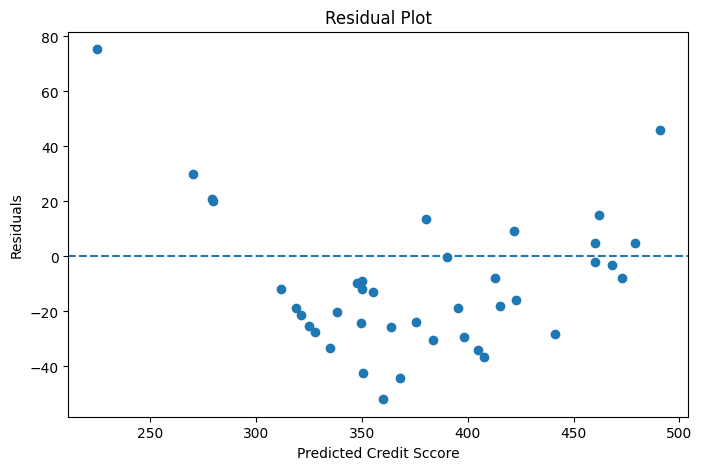

In [67]:
# Residuals

residuals = Y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals)

plt.axhline(y=0,  linestyle="--")

plt.xlabel("Predicted Credit Sccore")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [72]:
X = df.drop("Applicant_ID", axis=1)

print(X)

     Age  Annual_Income_INR  Debt_to_Income_Ratio  Late_Payments_12M  \
0     61             576000                  0.07                  4   
1     26            1536000                  0.07                  1   
2     56             840000                  0.50                  8   
3     31            1536000                  0.26                  2   
4     26            1404000                  0.11                  5   
..   ...                ...                   ...                ...   
195   51            1008000                  0.07                  3   
196   62            1248000                  0.22                  5   
197   32            1764000                  0.49                  5   
198   48             480000                  0.32                  2   
199   49            1548000                  0.15                  7   

     Credit_History_Years  Credit_Utilization_Ratio  Existing_Loans  \
0                       8                      0.24             